# Исследование данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
import numpy as np
from datasets import Dataset
from transformers import (
AutoModelForSequenceClassification,
AutoTokenizer,
Trainer,
TrainingArguments,
set_seed
)
from time import perf_counter
import torch

## Задача
Датасет banking77 состоит из набора текстовых запросов в службу поддержки банка. Каждый запрос имеет одну из 77 меток - намерение запроса. Именно эту метку необходимо научиться предсказывать. Имеем датасет train, содержащий 10 003 записей, и test, содержащий 3 080 записей.

In [2]:
train_df = pd.read_parquet("/kaggle/input/datasets/alenaglushkova1/banking77/train-00000-of-00001.parquet")
test_df = pd.read_parquet("/kaggle/input/datasets/alenaglushkova1/banking77/test-00000-of-00001.parquet")

In [3]:
train_df.head(3)

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11


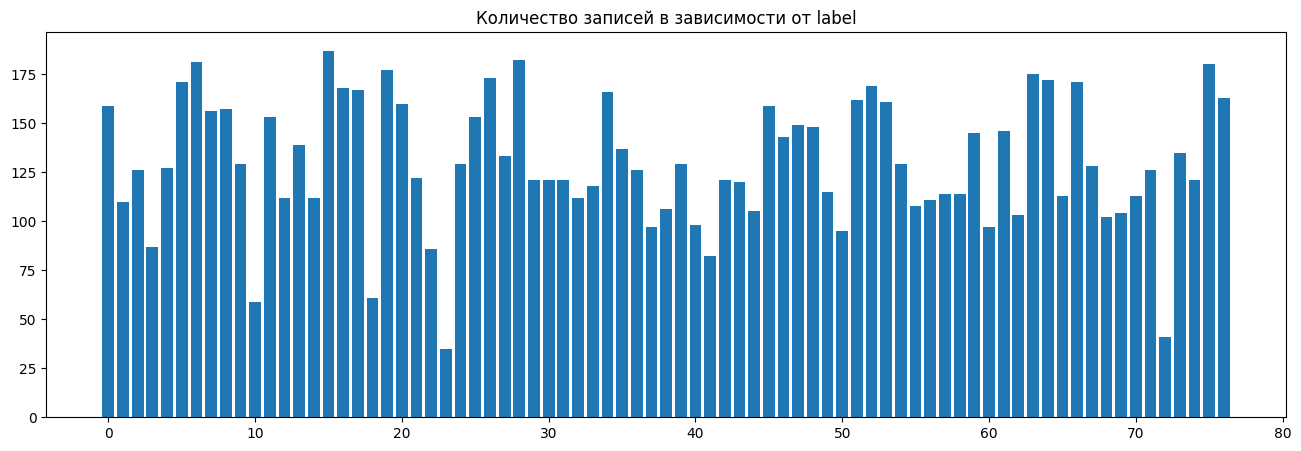

In [4]:
plt.figure(figsize=(16, 5))
plt.bar(train_df["label"].value_counts().sort_index().index, train_df["label"].value_counts().sort_index().values)
plt.title("Количество записей в зависимости от label")
plt.show()

Минимальное количество записей у одной метки - 23 (у contactless_not_working). Максимальное - 187 (card_payment_fee_charged). Разница большая. Можно ожидать, что модель хуже будет предсказывать редкий класс.

In [5]:
label_to_id = {
    "activate_my_card": 0,
    "age_limit": 1,
    "apple_pay_or_google_pay": 2,
    "atm_support": 3,
    "automatic_top_up": 4,
    "balance_not_updated_after_bank_transfer": 5,
    "balance_not_updated_after_cheque_or_cash_deposit": 6,
    "beneficiary_not_allowed": 7,
    "cancel_transfer": 8,
    "card_about_to_expire": 9,
    "card_acceptance": 10,
    "card_arrival": 11,
    "card_delivery_estimate": 12,
    "card_linking": 13,
    "card_not_working": 14,
    "card_payment_fee_charged": 15,
    "card_payment_not_recognised": 16,
    "card_payment_wrong_exchange_rate": 17,
    "card_swallowed": 18,
    "cash_withdrawal_charge": 19,
    "cash_withdrawal_not_recognised": 20,
    "change_pin": 21,
    "compromised_card": 22,
    "contactless_not_working": 23,
    "country_support": 24,
    "declined_card_payment": 25,
    "declined_cash_withdrawal": 26,
    "declined_transfer": 27,
    "direct_debit_payment_not_recognised": 28,
    "disposable_card_limits": 29,
    "edit_personal_details": 30,
    "exchange_charge": 31,
    "exchange_rate": 32,
    "exchange_via_app": 33,
    "extra_charge_on_statement": 34,
    "failed_transfer": 35,
    "fiat_currency_support": 36,
    "get_disposable_virtual_card": 37,
    "get_physical_card": 38,
    "getting_spare_card": 39,
    "getting_virtual_card": 40,
    "lost_or_stolen_card": 41,
    "lost_or_stolen_phone": 42,
    "order_physical_card": 43,
    "passcode_forgotten": 44,
    "pending_card_payment": 45,
    "pending_cash_withdrawal": 46,
    "pending_top_up": 47,
    "pending_transfer": 48,
    "pin_blocked": 49,
    "receiving_money": 50,
    "Refund_not_showing_up": 51,
    "request_refund": 52,
    "reverted_card_payment?": 53,
    "supported_cards_and_currencies": 54,
    "terminate_account": 55,
    "top_up_by_bank_transfer_charge": 56,
    "top_up_by_card_charge": 57,
    "top_up_by_cash_or_cheque": 58,
    "top_up_failed": 59,
    "top_up_limits": 60,
    "top_up_reverted": 61,
    "topping_up_by_card": 62,
    "transaction_charged_twice": 63,
    "transfer_fee_charged": 64,
    "transfer_into_account": 65,
    "transfer_not_received_by_recipient": 66,
    "transfer_timing": 67,
    "unable_to_verify_identity": 68,
    "verify_my_identity": 69,
    "verify_source_of_funds": 70,
    "verify_top_up": 71,
    "virtual_card_not_working": 72,
    "visa_or_mastercard": 73,
    "why_verify_identity": 74,
    "wrong_amount_of_cash_received": 75,
    "wrong_exchange_rate_for_cash_withdrawal": 76,
}

Некоторые категории намерений могут быть трудно разделимы, поскольку их смыслы могут пересекаться. Посмотрим на несколько примеров текстов обращений из групп, которые предположительно похожи между собой.

Сравним balance_not_updated_after_bank_transfer и balance_not_updated_after_cheque_or_cash_deposit.

In [6]:
for query in train_df.loc[train_df["label"] == label_to_id["balance_not_updated_after_bank_transfer"], "text"].head(10):
    print(query)
    print()

help my money isnt showing up

how do i see what i transferred

Hello. Can you help figure out why the recent transfer from my UK bank account isn't showing up?

I've made a transfer from France two days ago but I was wondering if international transfers take longer to arrive because it hasn't made it yet.

After I transferred money the balance remained the same.

Where is the money that I transferred.

About two days ago now, I made a transfer from France but it hasn't arrived yet. Is it possible that the international transfer just takes longer?

Why is my balance the same after a transfer?

How long will it take for a bank transfer to show up on my account? It's been a couple hours but I havnt seen anything yet. Also it's from a UK account if that makes any difference.

The transfer I made isn't reflected in my balance



In [7]:
for query in train_df.loc[train_df["label"] == label_to_id["balance_not_updated_after_cheque_or_cash_deposit"], "text"].head(10):
    print(query)
    print()

Why is my last cheque deposit taking so long?

I am still waiting for a the cash I deposited this morning

I tried using a check to update my balance, but it isn't work? Is something wrong?

I deposited cash but it isn't showing up in my account

I put some cash into my account but it's not displaying that on my balance.

Why hasn't my cash been deposited yet?

Hi, I want to inquire about my balance. Some cash was deposited and it hasn't updated yet.

I deposited a check yesterday and im not seeing it posted yet in my account. why is that? can you look into it?

I made a deposit a couple of days back it's, as of yet, not gone in! It would be ideal if you assist me with this

The cheque I sent a few days ago has not been deposited yet, what is the hold up?



Есть неоднозначные запросы, например:
- help my money isnt showing up — не указан способ пополнения.
- I made a deposit a couple of days back... — нет ни cash, ни cheque.

card_arrival / card_delivery_estimate - «где моя карта?» и «когда доставят карту?». Здесь формулировки могут сильно пересекаться.

In [8]:
for query in train_df.loc[train_df["label"] == label_to_id["card_arrival"], "text"].head(10):
    print(query)
    print()

I am still waiting on my card?

What can I do if my card still hasn't arrived after 2 weeks?

I have been waiting over a week. Is the card still coming?

Can I track my card while it is in the process of delivery?

How do I know if I will get my card, or if it is lost?

When did you send me my new card?

Do you have info about the card on delivery?

What do I do if I still have not received my new card?

Does the package with my card have tracking?

I ordered my card but it still isn't here



In [9]:
for query in train_df.loc[train_df["label"] == label_to_id["card_delivery_estimate"], "text"].head(10):
    print(query)
    print()

Can it specifically be delivered on a certain date?

I need to get my card quickly

When can I expect my card? I live in the US.

Help! When will the card arrive at my home?

Can I get my card fast tracked?

How long is the wait for my card?

i need to expedite my card

When should I expect to receive my card?

How long until my card will get here?

How long is the delivery time to the US?



Граница между классами размыта: вопрос «When will the card arrive at my home?» может означать и запрос ожидаемого срока, и уточнение статуса конкретной доставки. Поэтому можно ожидать, что модель будет путать эти интенты, когда в тексте нет явных признаков задержки, отслеживания или срочности.

Все запросы имеют минимум 13 символов. Большая часть из них меньше 100 символов. Есть те, что более 100 символов и меньше 400, но они не являются аномальными. Пропусков в данных нет, как и пустых запросов. Также отстуствуют дубликаты.

## Выводы по данным
Тексты в целом читаемые, но чистота текста и однозначность метки - разные вещи. Некоторые метки действительно неоднозначные, поэтому модель может путать их. 

Есть и небольшие ошибки: isnt, havnt, im, it isn't work.

Присутствует дисбаланс классов.

Аномалии в данных отстуствуют.

# Подготовка данных

Для выбора модели и её настройки используем обучающую выборку, разделив её на локальный трейн и валидационную выборку. Для всех экспериментов используем одинаковое разбиение.

In [10]:
id_to_label = {val: key for key, val in label_to_id.items()}

In [11]:
train, val = train_test_split(train_df, test_size=0.2, random_state=42, stratify=train_df["label"])

In [12]:
X_train = train["text"]
X_val = val["text"]
y_train = train["label"]
y_val = val["label"]

# Обучение базовой модели

В качестве базовой модели будем использовать логистическую регрессию, обученную на TF-IDF векторах. Для каждого запроса формируется TF-IDF вектор длины, равной длине словаря всех слов. На этих векторах обучается логрегрессия, предсказывающая одну из 77 меток.

In [13]:
pipe = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("logreg", LogisticRegression())
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_val)

print("Macro f1-score:")
f1 = f1_score(y_val, y_pred, average="macro")
print(f1)
print("Accuracy score:")
accuracy = accuracy_score(y_val, y_pred)
print(accuracy)

Macro f1-score:
0.8411856427948405
Accuracy score:
0.8490754622688655


Для улучшения качества модели с помощью GridSearchCV были исследованы следующие параметры:
- С 
- ngram_range
- min_df
- analyzer="char"

По итогу лучшей из опробованных моделей оказалась модель, обученная на символьном TF-IDF, с наборами символов размерами 3-5, с регуляризацией логрегрессии 10.

In [14]:
pipe.set_params(vectorizer__ngram_range=(3,5), vectorizer__analyzer="char_wb", logreg__C=10)
pipe.fit(X_train, y_train)
y_pred=pipe.predict(X_val)

print("Macro f1-score:")
f1 = f1_score(y_val, y_pred, average="macro")
print(f1)
print("Accuracy score:")
accuracy = accuracy_score(y_val, y_pred)
print(accuracy)

Macro f1-score:
0.8841787811202595
Accuracy score:
0.887056471764118


Краткая сводка по остальным экспериментам:

### Сравнение моделей на валидационной выборке

| Модель | Представление текста и параметры | Macro F1 | Accuracy |
| --- | --- | ---: | ---: |
| Логистическая регрессия (baseline) | TF-IDF по отдельным словам, `C=1` | 0.841186 | 0.849075 |
| Логистическая регрессия | TF-IDF по отдельным словам и парам соседних слов, `C=1` | 0.830666 | 0.841579 |
| Логистическая регрессия | TF-IDF по отдельным словам, `C=10` | 0.870701 | 0.874563 |
| **Логистическая регрессия** | **Символьный TF-IDF внутри слов, n-граммы длиной 3–5, `C=10`** | **0.884179** | **0.887056** |
| Логистическая регрессия | Символьный TF-IDF внутри слов, n-граммы длиной 2–5, `C=10`, `min_df=3` | 0.879573 | 0.882559 |
| LinearSVC | TF-IDF по отдельным словам, `C=1` | 0.866337 | 0.872564 |
| LinearSVC | Символьный TF-IDF внутри слов, n-граммы длиной 3–5, `C=1`, `max_iter=10000` | 0.877729 | 0.880560 |
| Логистическая регрессия | Символьный TF-IDF после лемматизации, n-граммы длиной 3–5, `C=10` | 0.880730 | 0.886057 |

Лучший Macro F1 на валидации показала логистическая регрессия с символьным TF-IDF по n-граммам длиной 3–5. Она улучшила результат словного baseline с 0.8412 до 0.8842. Лемматизация при тех же настройках символьного TF-IDF дала 0.8807, поэтому для финального сравнения выбрана модель на исходных текстах.

# Дообучение трансформера

Попробуем использовать более сложные модели для классификации отзывов:

**BERT Base** состоит из слоя эмбеддингов и 12 блоков Transformer-энкодера. Его предобучили на английской Википедии и BookCorpus.

**DistilBERT** состоит из слоя эмбеддингов и 6 блоков Transformer-энкодера. Его предобучили на тех же корпусах с помощью дистилляции: меньшая модель училась воспроизводить предсказания BERT Base. У обеих моделей размер скрытого представления токена - 768.

К каждой модели добавили классификационную голову на 77 категорий. Подавали исходные тексты обращений, токенизированные с ограничением в 128 токенов, и обновляли все веса, включая энкодер и новую голову.

In [20]:
def train_transformer(model_name):
    set_seed(42)
    
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    
    def make_dataset(X, y):
        X_tokenized = tokenizer(list(X), truncation=True, max_length=128)
        return Dataset.from_dict({**X_tokenized, "labels": list(y)})
    
    train_dataset = make_dataset(X_train, y_train)
    val_dataset = make_dataset(X_val, y_val)
    
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=77)
    
    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
    
        return {
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
            "accuracy": accuracy_score(labels, preds)
        }
    
    training_args = TrainingArguments(
        learning_rate=3e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=20,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="no",
        load_best_model_at_end=False,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        seed=42,
    )
    
    trainer = Trainer(
        model = model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )
    trainer.train()
    if model_name == "google-bert/bert-base-uncased":
        trainer.save_model("/kaggle/working/banking77_bert")
    else:
        trainer.save_model("/kaggle/working/banking77_distilbert")
    return trainer.state.log_history

Результаты тестирования различных гиперпараметров трансформера на валидационной выборке:

| Модель | Начальный LR | Лимит эпох | Лучшая эпоха | Val macro F1 | Val accuracy |
| --- | ---: | ---: | ---: | ---: | ---: |
| DistilBERT | `2e-5` | 4 | 4 | 0.872779 | 0.884058 |
| DistilBERT | `2e-5` | 8 | 8 | 0.885903 | 0.896052 |
| DistilBERT | `2e-5` | 12 | 12 | 0.902536 | 0.905047 |
| DistilBERT | `2e-5` | 20 | 17 | 0.912660 | 0.913043 |
| DistilBERT | `1e-5` | 20 | 16 | 0.893437 | 0.899550 |
| DistilBERT | `3e-5` | 20 | 17 | **0.914107** | **0.915042** |
| BERT Base | `3e-5` | 20 | 18 | **0.915461** | 0.914543 |

Видно, что по качеству выигрывают DistilBERT и BERT Base с learning_rate=3e-5 и количеством эпох 20. BERT Base немного обгоняет по значению метрики f1, однако это не повод выбрать эту модель, сначала сравним время инференса двух моделей.

In [16]:
%%capture distilbert_output
distilbert_history = train_transformer("distilbert/distilbert-base-uncased")

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [17]:
def make_metrics_table(history):
    metrics = pd.DataFrame(history)
    metrics = metrics.loc[
        metrics["eval_macro_f1"].notna(),
        ["epoch", "eval_loss", "eval_macro_f1", "eval_accuracy"],
    ].copy()

    metrics["epoch"] = metrics["epoch"].astype(int)

    return metrics.rename(columns={
        "epoch": "Epoch",
        "eval_loss": "Validation Loss",
        "eval_macro_f1": "Macro F1",
        "eval_accuracy": "Accuracy",
    }).reset_index(drop=True)

display(make_metrics_table(distilbert_history).round(6))

,Epoch,Validation Loss,Macro F1,Accuracy
0,1,4.227343,0.569695,0.653173
1,2,1.731552,0.817105,0.841079
2,3,1.010916,0.873504,0.888556
3,4,0.799080,0.888837,0.895552
4,5,0.786250,0.894931,0.897551
5,6,0.748118,0.899732,0.901549
6,7,0.755904,0.903993,0.904548
7,8,0.822836,0.906536,0.906547
8,9,0.846120,0.907334,0.907546
9,10,0.875857,0.904539,0.905047


In [29]:
%%capture bert_output
bert_history = train_transformer("google-bert/bert-base-uncased")

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [30]:
display(make_metrics_table(bert_history).round(6))

,Epoch,Validation Loss,Macro F1,Accuracy
0,1,4.198174,0.661789,0.714143
1,2,1.733191,0.843302,0.866067
2,3,1.021743,0.892921,0.897051
3,4,0.854036,0.896780,0.900550
4,5,0.797027,0.906321,0.907046
5,6,0.788195,0.904659,0.906047
6,7,0.808917,0.906746,0.907546
7,8,0.870853,0.911492,0.910545
8,9,0.911086,0.915284,0.914043
9,10,0.919960,0.909427,0.908546


# Время инференса моделей

Сравним время инференса BERT, DistilBERT, а также TD-IDF+logreg.

In [31]:
paths = {
    "DistilBert": "/kaggle/working/banking77_distilbert",
    "Bert": "/kaggle/working/banking77_bert"
}
rng = np.random.default_rng(42)
val_texts = list(X_val)
indices = rng.choice(len(val_texts), 300, replace=False)
texts = [val_texts[i] for i in indices]

def benchmark(model_path, texts):
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    model.to("cpu")
    model.eval()

    def predict(text):
        inputs = tokenizer(text, truncation=True, max_length=128, return_tensors="pt")
        logits = model(**inputs).logits
        return logits.argmax(dim=-1).item()
    times_ms = []
    with torch.inference_mode():
        for text in texts[:20]:
            predict(text)
        for text in texts:
            start = perf_counter()
            predict(text)
            times_ms.append((perf_counter() - start) * 1000)
    return {
        "median_ms": np.median(times_ms),
        "p95_ms": np.percentile(times_ms, 95)
    }
speed_results = pd.DataFrame({
    "model": name, **benchmark(path, texts)} for name, path in paths.items())

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [32]:
pipe = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("logreg", LogisticRegression())
])
pipe.set_params(vectorizer__ngram_range=(3,5), vectorizer__analyzer="char_wb", logreg__C=10)
pipe.fit(X_train, y_train)

Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5))),
                ('logreg', LogisticRegression(C=10))])

In [33]:
rng = np.random.default_rng(42)
val_texts = list(X_val)
indices = rng.choice(len(val_texts), 300, replace=False)
texts = [val_texts[i] for i in indices]

def benchmark(model, texts):
    times_ms = []
    
    for text in texts[:20]:
        model.predict([text])
    for text in texts:
        start = perf_counter()
        model.predict([text])
        times_ms.append((perf_counter() - start) * 1000)
    return {
        "median_ms": np.median(times_ms),
        "p95_ms": np.percentile(times_ms, 95)
    }
speed_results.loc[len(speed_results)] = ["TF-IDF+logreg", *benchmark(pipe, texts).values()]
speed_results.round(2)

,model,median_ms,p95_ms
0,DistilBert,29.87,40.91
1,Bert,56.62,74.28
2,TF-IDF+logreg,2.66,2.97


При обработке одного запроса на CPU быстрее всего оказался TF‑IDF + логистическая регрессия с медианной задержкой около 3 мс. У DistilBERT она составила 32 мс, почти вдвое меньше, чем у BERT-base (62 мс). На 95-м перцентиле порядок сохранился: 3,38 мс у TF‑IDF, 45,29 мс у DistilBERT и 84,99 мс у BERT-base.

# Качество на тестовой выборке

Теперь сравним качество моделей на тестовой выборке, обучив их заново на train и val.

In [35]:
X_train_val = train_df["text"]
y_train_val = train_df["label"]
X_test = test_df["text"]
y_test = test_df["label"]

In [36]:
pipe = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("logreg", LogisticRegression())
])
pipe.set_params(vectorizer__ngram_range=(3,5), vectorizer__analyzer="char_wb", logreg__C=10)
pipe.fit(X_train_val, y_train_val)
y_pred = pipe.predict(X_test)
print(f"TD-IDF+logreg, f1:{f1_score(y_test, y_pred, average="macro")}")
print(f"TD-IDF+logreg, accuracy:{accuracy_score(y_test, y_pred)}")

TD-IDF+logreg, f1:0.9096367906974356
TD-IDF+logreg, accuracy:0.9097402597402597


In [40]:
%%capture distilbert_output

set_seed(42)
model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def make_dataset(X, y):
    X_tokenized = tokenizer(list(X), truncation=True, max_length=128)
    return Dataset.from_dict({**X_tokenized, "labels": list(y)})

train_dataset = make_dataset(X_train, y_train)
test_dataset = make_dataset(X_test, y_test)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=77)
training_args = TrainingArguments(
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=17,
    weight_decay=0.01,
    eval_strategy="no",
    load_best_model_at_end=False,
    report_to="none",
    seed=42,
)
def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
    
        return {
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
            "accuracy": accuracy_score(labels, preds)
        }
trainer = Trainer(
    model = model,
    args=training_args,
    train_dataset=train_dataset,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()
metrics=trainer.evaluate(eval_dataset=test_dataset)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [41]:
print(metrics["eval_macro_f1"])
print(metrics["eval_accuracy"])

0.9208016464429388
0.9207792207792208


На тестовой выборке DistilBERT показал лучшее качество по обеим метрикам. Macro F1 вырос с 0,9096 у TF‑IDF + логистической регрессии до 0,9298, а accuracy - с 0,9097 до 0,9299. При этом медианная задержка одного запроса на CPU у TF‑IDF была примерно в 11 раз ниже, поэтому выбор модели зависит от того, что важнее для задачи — качество классификации или скорость ответа.

In [42]:
import shutil
trainer.save_model("/kaggle/working/banking77_distilbert_final")
shutil.make_archive(
    "/kaggle/working/banking77_distilbert_final",
    "zip",
    root_dir="/kaggle/working",
    base_dir="banking77_distilbert_final",
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

'/kaggle/working/banking77_distilbert_final.zip'

# Анализ ошибок модели

Сравним предсказания TF‑IDF и DistilBERT на тестовой выборке и посмотрим, какие интенты каждая модель путает чаще всего.

In [43]:
y_bert_pred = trainer.predict(test_dataset).predictions.argmax(axis=-1)
all_preds = pd.concat([X_test, y_test, 
                       pd.Series(y_pred, index=X_test.index, name="logreg_pred"),
                       pd.Series(y_bert_pred, index=X_test.index, name="distilbert_pred"),
                      ], axis=1)
all_preds["true_label_name"] = all_preds["label"].apply(lambda x: id_to_label[x])
all_preds["logreg_pred_label_name"] = all_preds["logreg_pred"].apply(lambda x: id_to_label[x])
all_preds["distilbert_pred_label_name"] = all_preds["distilbert_pred"].apply(lambda x: id_to_label[x])

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [44]:
all_preds[all_preds["true_label_name"] != all_preds["distilbert_pred_label_name"]]\
.groupby(by=["true_label_name", "distilbert_pred_label_name"])["true_label_name"].count().sort_values(ascending=False)\
.reset_index(name="error_count").head(7)

,true_label_name,distilbert_pred_label_name,error_count
0,why_verify_identity,verify_my_identity,7
1,declined_transfer,declined_card_payment,5
2,card_payment_not_recognised,compromised_card,5
3,pending_transfer,balance_not_updated_after_bank_transfer,5
4,pin_blocked,change_pin,5
5,balance_not_updated_after_bank_transfer,transfer_timing,4
6,card_arrival,card_delivery_estimate,4


In [45]:
all_preds[all_preds["true_label_name"] != all_preds["logreg_pred_label_name"]]\
.groupby(by=["true_label_name", "logreg_pred_label_name"])["true_label_name"].count().sort_values(ascending=False)\
.reset_index(name="error_count").head(7)

,true_label_name,logreg_pred_label_name,error_count
0,why_verify_identity,verify_my_identity,6
1,virtual_card_not_working,get_disposable_virtual_card,5
2,pending_top_up,top_up_failed,4
3,top_up_failed,top_up_reverted,4
4,verify_my_identity,why_verify_identity,4
5,unable_to_verify_identity,why_verify_identity,4
6,pin_blocked,card_not_working,3


In [47]:
all_preds[(all_preds["true_label_name"] == "card_arrival") & 
(all_preds["distilbert_pred_label_name"] == "card_delivery_estimate")]

,text,label,logreg_pred,distilbert_pred,true_label_name,logreg_pred_label_name,distilbert_pred_label_name
3,Is there a way to know when my card will arrive?,11,11,12,card_arrival,card_arrival,card_delivery_estimate
5,When will I get my card?,11,12,12,card_arrival,card_delivery_estimate,card_delivery_estimate
11,How long does a card delivery take?,11,12,12,card_arrival,card_delivery_estimate,card_delivery_estimate
32,How do I know when my card will arrive?,11,12,12,card_arrival,card_delivery_estimate,card_delivery_estimate


У обеих моделей среди самых частых ошибок встречаются смыслово близкие интенты. Например, DistilBERT отнёс четыре запроса с меткой card_arrival к card_delivery_estimate. В трёх из этих четырёх случаев TF‑IDF ошибся так же. Формулировка “How long does a card delivery take?” звучит как вопрос о сроке доставки, хотя в датасете у неё метка card_arrival. Это согласуется с наблюдением из EDA о том, что формулировки двух классов пересекаются.

In [48]:
all_preds[(all_preds["true_label_name"] == "why_verify_identity") & 
(all_preds["logreg_pred_label_name"] == "verify_my_identity")]

,text,label,logreg_pred,distilbert_pred,true_label_name,logreg_pred_label_name,distilbert_pred_label_name
1165,What is the need to verify my identity?,74,69,69,why_verify_identity,verify_my_identity,verify_my_identity
1176,What is the point of an identity check?,74,69,74,why_verify_identity,verify_my_identity,why_verify_identity
1177,How come you need to know my identity?,74,69,74,why_verify_identity,verify_my_identity,why_verify_identity
1191,what is the identity check?,74,69,74,why_verify_identity,verify_my_identity,why_verify_identity
1192,What other methods are there to verify my iden...,74,69,69,why_verify_identity,verify_my_identity,verify_my_identity
1193,Do I need to verify my identity?,74,69,69,why_verify_identity,verify_my_identity,verify_my_identity


Для пары why_verify_identity → verify_my_identity у TF‑IDF было шесть ошибок. В трёх из этих шести случаев DistilBERT предсказал верный интент. Например, он правильно распознал “What is the point of an identity check?” как вопрос о цели проверки. При этом на похожем запросе “What is the need to verify my identity?” ошиблись обе модели. DistilBERT лучше справился с частью таких формулировок, но различие между этими интентами по-прежнему вызывает ошибки.

## Вывод

DistilBERT реже ошибается на тестовой выборке, но обе модели всё ещё путают близкие по смыслу интенты. В некоторых запросах сама формулировка допускает несколько трактовок, поэтому даже при высоком Macro F1 граница между отдельными классами остаётся сложной.